# 15. Lateral Shear Transformations Between Periodic Layers Without Re-Solving Eigenmodes

## Physical Motivation & Learning Objectives
When two periodic layers are shifted laterally by $\Delta x$, Bloch theorem states that the transverse field profiles undergo an exact diagonal phase shift:
$$e_m(x - \Delta x, y) = e_m(x, y) \exp(-i k_{x, m} \Delta x)$$
In EMUstack, lateral translation is implemented via the `shear` argument in `Stack`.
In this tutorial:
1. We compute layer eigenmodes once.
2. We continuously sweep lateral displacement $\Delta x / \Lambda$ without re-meshing or re-solving modes.
3. We analyze transmission variations vs lateral alignment.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Layer Setup: Two Identical 1D Gratings


In [2]:
wl = 800.0      # nm
period = 760.0  # nm

light = objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0)

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.45), world_1d=True, loss=False)

grating_1 = objects.NanoStruct(
    '1D_array', period,
    diameter1=int(round(0.25 * period)),
    diameter2=int(round(0.25 * period)),
    small_space=period / 2.0,
    height_nm=150.0,
    inclusion_a=materials.Material(3.61),
    inclusion_b=materials.Material(3.61),
    background=materials.Material(1.46),
    loss=True, lc_bkg=0.01, plt_msh=False
)

# Calculate modes once!
sim_sup = superstrate.calc_modes(light)
sim_sub = substrate.calc_modes(light)
sim_g1  = grating_1.calc_modes(light, num_BMs=20)


## Sweeping Lateral Shear Parameter $\Delta x$


<ipython-input-1-83fab70955c9>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


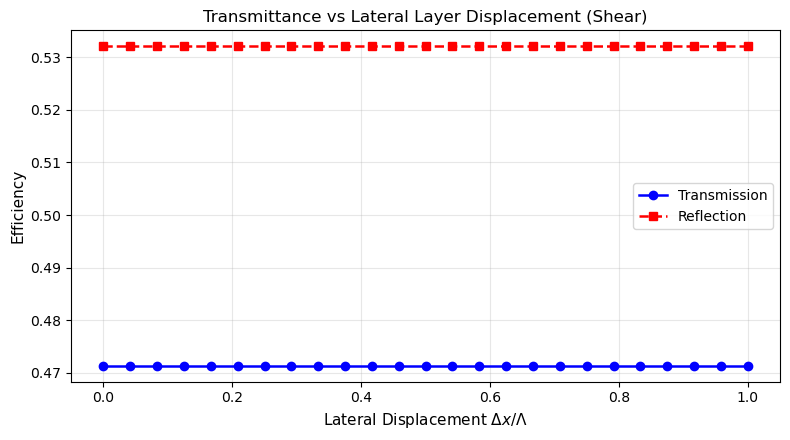

In [3]:
shears = np.linspace(0.0, period, 25)
t_shear = []
r_shear = []

for dx in shears:
    # Shift top grating relative to bottom
    stk = Stack((sim_sub, sim_g1, sim_g1, sim_sup), shears=[(0.0, 0.0), (0.0, 0.0), (dx / period, 0.0), (0.0, 0.0)])
    stk.calc_scat(pol='TE')
    t_shear.append(float(stk.t_list[-1]))
    r_shear.append(float(stk.r_list[-1]))

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=100)
ax.plot(shears / period, t_shear, 'b-o', lw=1.8, label='Transmission')
ax.plot(shears / period, r_shear, 'r--s', lw=1.8, label='Reflection')
ax.set_xlabel(r'Lateral Displacement $\Delta x / \Lambda$', fontsize=11)
ax.set_ylabel('Efficiency', fontsize=11)
ax.set_title('Transmittance vs Lateral Layer Displacement (Shear)', fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Physical Interpretation
- Reusing the pre-computed layer modes enables ultra-fast evaluation of multi-layer alignment tolerances.
- Transmission exhibits periodic Fabry–Pérot modulation as the lateral overlap alternates between aligned and staggered configurations.
